# Przetwarzanie języka naturalnego (NLP) - analiza sentymentu, klasyfikacja dokumentów.

# Instalacja porzebnych bibliotek:

In [ ]:
!pip install datasets --quiet && echo "Biblioteka 'datasets' została zainstalowana"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.2/491.2 kB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.9/183.9 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 143.5/143.5 kB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 194.8/194.8 kB 10.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.3.2 requires fsspec==2025.3.2, but you have fsspec 2024.12.0 which is incompatible.
torch 2.6.0+cu124 requires nvidia-cublas-cu12==12.4.5.8; platform_system == "Linux" and platform_machine == "x86_64", but you have nvidia-cublas-cu12 12.5.3.2 which is incompatible.
torch 2.6.0+cu124 requires nvidia-cuda-cupti-cu12==12.4.127; platform_system == "Linux" and platform_machine == "x86_64", but you have nvidia-cuda-

# Zaimportowanie potrzebnych bibliotek:

In [2]:
import re
import nltk
import matplotlib.pyplot as plt
import seaborn as sns
import sys

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
from datasets import load_dataset
from sklearn.metrics import accuracy_score, classification_report
from nltk.sentiment import SentimentIntensityAnalyzer

# Zbiór danych do analizy sentymentów:

IMDB Reviews (opinie filmowe)

50 000 recenzji filmowych z IMDB

Każda recenzja oznaczona jako pozytywna (1) lub negatywna (0)

In [3]:
dataset = load_dataset("imdb")
# Wczytanie danych

/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

train-00000-of-00001.parquet:   0%|          | 0.00/21.0M [00:00<?, ?B/s]

test-00000-of-00001.parquet:   0%|          | 0.00/20.5M [00:00<?, ?B/s]

unsupervised-00000-of-00001.parquet:   0%|          | 0.00/42.0M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

# Wyswietlenie pierwszych dziesięciu recenzji oraz ich sentymentu:

In [4]:
for i in range(10):
    print(f"Text: {dataset['train'][i]['text']}")
    print(f"Sentiment: {'Positive' if dataset['train'][i]['label'] == 1 else 'Negative'}")
    print("-" * 80)

Text: I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political issues such as the Vietnam War and race issues in the United States. In between asking politicians and ordinary denizens of Stockholm about their opinions on politics, she has sex with her drama teacher, classmates, and married men.<br /><br />What kills me about I AM CURIOUS-YELLOW is that 40 years ago, this was considered pornographic. Really, the sex and nudity scenes are few and far betwee

# Wykres liczby pozytywnych i negatywnych recenzji w zbiorze treningowym:

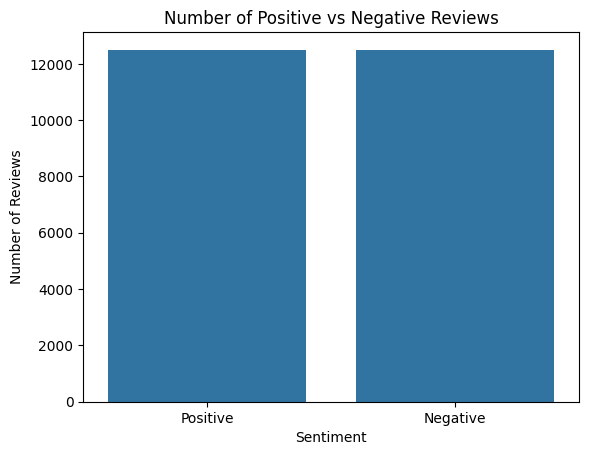

In [5]:
positive_count = sum(1 for label in dataset['train']['label'] if label == 1)
negative_count = sum(1 for label in dataset['train']['label'] if label == 0)

labels = ['Positive', 'Negative']
counts = [positive_count, negative_count]

sns.barplot(x=labels, y=counts)
plt.title('Number of Positive vs Negative Reviews')
plt.ylabel('Number of Reviews')
plt.xlabel('Sentiment')
plt.show()

W tej części czyścimy tekst:
- usuwamy podwójne spacje oraz znaki specjalne;
- usuwamy stopworsds (np: the, in, on);
- konwersujemy tekst na małe litery.

Tworzymy wektory tekstu za pomocą TfidVectiorizer

In [6]:
nltk.download("stopwords")
nltk.download("vader_lexicon")
stop_words = set(stopwords.words("english"))
sia = SentimentIntensityAnalyzer()

def clean_text(text):
    text = re.sub(r"\W", " ", text)
    text = re.sub(r"\s+", " ", text)
    text = text.lower()
    words = text.split()
    words = [word for word in words if word not in stop_words]
    return " ".join(words)

dataset = dataset.map(lambda x: {"clean_text": clean_text(x["text"])})

vectorizer = TfidfVectorizer(max_features=5000)
X_train = vectorizer.fit_transform(dataset["train"]["clean_text"])
X_test = vectorizer.transform(dataset["test"]["clean_text"])
y_train = dataset["train"]["label"]
y_test = dataset["test"]["label"]

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package vader_lexicon to /root/nltk_data...


Map:   0%|          | 0/25000 [00:00<?, ? examples/s]

Map:   0%|          | 0/25000 [00:00<?, ? examples/s]

Map:   0%|          | 0/50000 [00:00<?, ? examples/s]

# Trenowanie modeli oraz wyświetlenie ich wyników:


LogisticRegression jest to klasyfikator stosowany do rozwiązywania problemów klasyfikacji binarnej lub wieloklasowej. Jest szeroko stosowany w zadaniach klasyfikacji, w tym w klasyfikacji sentymentu, czyli przypisaniu etykiety pozytywnej lub negatywnej do tekstu.

In [7]:
model = LogisticRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.88104
              precision    recall  f1-score   support

           0       0.88      0.88      0.88     12500
           1       0.88      0.88      0.88     12500

    accuracy                           0.88     25000
   macro avg       0.88      0.88      0.88     25000
weighted avg       0.88      0.88      0.88     25000



Macierz błędów:

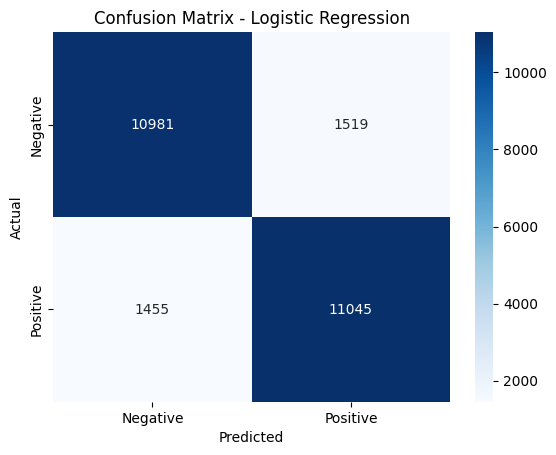

In [8]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Negative", "Positive"], yticklabels=["Negative", "Positive"])
plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

Analizując macierz błędów można zauważyc:
- True Negatives (TN) = 10981: Model poprawnie sklasyfikował 10981 negatywnych przypadków.

- False Positives (FP) = 1519: Model błędnie sklasyfikował 1519 negatywnych przypadków jako pozytywne.

- False Negatives (FN) = 1455: Model błędnie sklasyfikował 1455 pozytywnych przypadków jako negatywne.

- True Positives (TP) = 11045: Model poprawnie sklasyfikował 11045 pozytywnych przypadków.

VADER (Valence Aware Dictionary and sEntiment Reasoner) to narzędzie do analizy sentymentu, które jest szczególnie skuteczne w przypadku analizy krótkich tekstów, takich jak tweety, recenzje lub posty na forach. Jest to model oparty na regułach, który wykorzystuje słownik słów i fraz, z odpowiednimi wagami określającymi ich emocjonalne zabarwienie, do oceniania nastroju tekstu.



In [9]:
y_pred_vader = [1 if sia.polarity_scores(text)['compound'] >= 0.05 else 0 for text in dataset["test"]["text"]]

print("Accuracy (VADER):", accuracy_score(y_test, y_pred_vader))
print(classification_report(y_test, y_pred_vader))

Accuracy (VADER): 0.69972
              precision    recall  f1-score   support

           0       0.79      0.54      0.64     12500
           1       0.65      0.86      0.74     12500

    accuracy                           0.70     25000
   macro avg       0.72      0.70      0.69     25000
weighted avg       0.72      0.70      0.69     25000



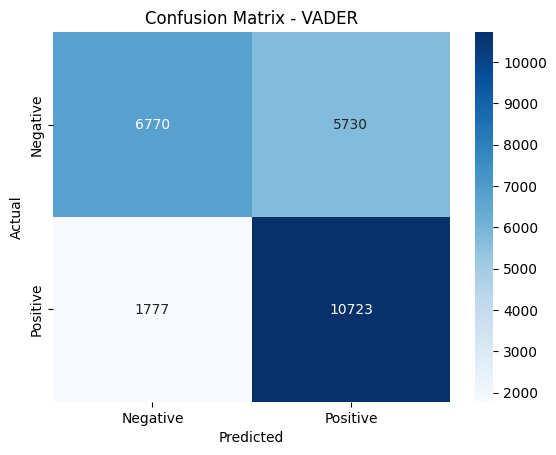

In [10]:
cm_vader = confusion_matrix(y_test, y_pred_vader)
sns.heatmap(cm_vader, annot=True, fmt="d", cmap="Blues", xticklabels=["Negative", "Positive"], yticklabels=["Negative", "Positive"])
plt.title("Confusion Matrix - VADER")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

Analizując macierz błędów można zauważyc:

- True Negatives (TN) = 6770: Model poprawnie sklasyfikował 6770 negatywnych przypadków.

- False Positives (FP) = 5730: Model błędnie sklasyfikował 5730 negatywnych przypadków jako pozytywne.

- False Negatives (FN) = 1777: Model błędnie sklasyfikował 1777 pozytywnych przypadków jako negatywne.

- True Positives (TP) = 10723: Model poprawnie sklasyfikował 10723 pozytywnych przypadków.

# Porównanie dokładności modeli:

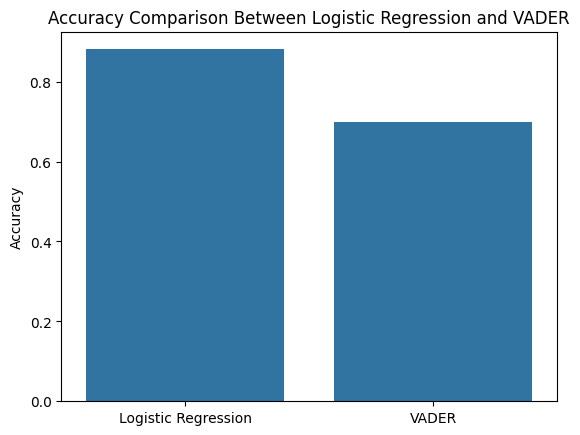

In [11]:
models = ["Logistic Regression", "VADER"]
accuracies = [accuracy_score(y_test, y_pred), accuracy_score(y_test, y_pred_vader)]

sns.barplot(x=models, y=accuracies)
plt.title("Accuracy Comparison Between Logistic Regression and VADER")
plt.ylabel("Accuracy")
plt.show()

Logistic Regression
- Model osiągnął wysoką dokładność na zbiorze testowym, wyraźnie przewyższając VADER.

- Skutecznie rozróżnia pozytywne i negatywne recenzje, nawet jeśli są dłuższe i bardziej złożone.

- Zastosowanie czyszczenia tekstu (clean_text) i ekstrakcji cech przez TF-IDF znacząco wpłynęło na jakość modelu.

VADER:
- VADER radzi sobie słabo na recenzjach z IMDB – jego dokładność była wyraźnie niższa niż modelu ML.

- Jako model oparty na słowniku, nie uwzględnia kontekstu i może się mylić przy dłuższych, wieloznacznych wypowiedziach.

- Najlepiej sprawdza się na krótkich, jednoznacznych tekstach (np. tweetach, komentarzach, nagłówkach).


# Przygotowanie nowych recenzji oraz wypisywanie ich sentymentu:

In [12]:
new_reviews = [
    "This movie was absolutely amazing! I loved every moment of it.",
    "The film was a total disaster. I regret watching it.",
    "A very mediocre experience, nothing special but not terrible either.",
    "The acting was great, but the story was predictable and boring.",
    "I had so much fun watching this movie! Highly recommend it.",
    "It was the worst film I have ever seen. A complete waste of time."
]

X_new = vectorizer.transform(new_reviews)
new_predictions = model.predict(X_new)

test_results = list(zip(new_reviews, new_predictions))
for review, sentiment in test_results:
    print(f"Review: {review}\nPredicted Sentiment: {'Positive' if sentiment == 1 else 'Negative'}\n")


Review: This movie was absolutely amazing! I loved every moment of it.
Predicted Sentiment: Positive

Review: The film was a total disaster. I regret watching it.
Predicted Sentiment: Negative

Review: A very mediocre experience, nothing special but not terrible either.
Predicted Sentiment: Negative

Review: The acting was great, but the story was predictable and boring.
Predicted Sentiment: Negative

Review: I had so much fun watching this movie! Highly recommend it.
Predicted Sentiment: Positive

Review: It was the worst film I have ever seen. A complete waste of time.
Predicted Sentiment: Negative



# Ocena sentymentu w czasie rzeczywistym:

In [13]:
def predict_sentiment(review, vectorizer, model):
    transformed_review = vectorizer.transform([review])
    prediction = model.predict(transformed_review)[0]
    return "Positive" if prediction == 1 else "Negative"

print("Enter a movie review (type 'q' to quit):")
while True:
    user_input = input("Your review: ")
    if user_input.lower() == "q":
        print("Exiting...")
        sys.exit()
    sentiment = predict_sentiment(user_input, vectorizer, model)
    print(f"Predicted Sentiment: {sentiment}\n")

Enter a movie review (type 'q' to quit):
Your review: q
Exiting...


SystemExit: 

/usr/local/lib/python3.11/dist-packages/IPython/core/interactiveshell.py:3561: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)
